<a href="https://colab.research.google.com/github/samritha07/Deep-Learning/blob/main/S_SAMRITHA_24BAD103_DL_SELF_LEARNING.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip -q install gensim nltk transformers scikit-learn matplotlib seaborn

In [2]:

import nltk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from nltk.corpus import brown
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity

nltk.download('brown')
nltk.download('punkt')
nltk.download('punkt_tab')

# Load the common text dataset
sentences = brown.sents()
documents = brown.sents(categories=None)

# Convert sentences into text
texts = [' '.join(sentence) for sentence in documents]

# Prepare tokenized sentences for Word2Vec and FastText
tokenized_sentences = [
    [word.lower() for word in sentence if word.isalpha()]
    for sentence in sentences
]
tokenized_sentences = [
    sentence for sentence in tokenized_sentences if len(sentence) > 1
]

print("Number of documents:", len(texts))
print("Number of tokenized sentences:", len(tokenized_sentences))
print("Sample text:", texts[0][:300])


[nltk_data] Downloading package brown to /root/nltk_data...
[nltk_data]   Package brown is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


Number of documents: 57340
Number of tokenized sentences: 55820
Sample text: The Fulton County Grand Jury said Friday an investigation of Atlanta's recent primary election produced `` no evidence '' that any irregularities took place .


In [3]:

tfidf_vectorizer = TfidfVectorizer(
    max_features=1000,
    stop_words='english'
)

tfidf_matrix = tfidf_vectorizer.fit_transform(texts[:3000])
feature_names = tfidf_vectorizer.get_feature_names_out()

print("TF-IDF matrix shape:", tfidf_matrix.shape)
print("First 20 vocabulary words:")
print(feature_names[:20])

# Display the most important words in the first document
first_doc_scores = tfidf_matrix[0].toarray().flatten()
top_indices = first_doc_scores.argsort()[-10:][::-1]

print("\nTop TF-IDF words in the first document:")
for index in top_indices:
    if first_doc_scores[index] > 0:
        print(feature_names[index], round(first_doc_scores[index], 4))


TF-IDF matrix shape: (3000, 1000)
First 20 vocabulary words:
['000' '10' '100' '11' '12' '13' '14' '15' '16' '17' '18' '19' '1958'
 '1959' '1960' '1961' '20' '200' '21' '22']

Top TF-IDF words in the first document:
investigation 0.305
fulton 0.2973
recent 0.2939
evidence 0.2939
primary 0.2877
grand 0.2877
atlanta 0.2849
place 0.2671
took 0.2671
friday 0.2529


In [4]:

from gensim.models import Word2Vec

word2vec_model = Word2Vec(
    sentences=tokenized_sentences,
    vector_size=100,
    window=5,
    min_count=2,
    workers=2,
    sg=1,
    epochs=10,
    seed=42
)

print("Word2Vec training completed!")
print("Vocabulary size:", len(word2vec_model.wv))
print("Vector for 'government':")
print(word2vec_model.wv['government'][:10])


Word2Vec training completed!
Vocabulary size: 24829
Vector for 'government':
[ 0.49287328  0.16888137  0.28640777 -0.16479377 -0.08586521  0.31121907
 -0.16526712  0.19080375 -0.31442004  0.13142315]


In [5]:

query_words = ['government', 'man', 'city', 'school', 'business']

for word in query_words:
    print(f"\nFive words similar to '{word}':")

    if word in word2vec_model.wv:
        for similar_word, score in word2vec_model.wv.most_similar(
            word, topn=5
        ):
            print(f"{similar_word}: {score:.4f}")
    else:
        print("Word not found in vocabulary.")



Five words similar to 'government':
representatives: 0.7781
coalition: 0.7781
belgian: 0.7776
jurisdiction: 0.7759
federal: 0.7724

Five words similar to 'man':
woman: 0.6648
himself: 0.6406
boy: 0.6257
victim: 0.6213
gentleman: 0.6066

Five words similar to 'city':
airport: 0.6960
yankees: 0.6957
kansas: 0.6952
jersey: 0.6816
pennsylvania: 0.6766

Five words similar to 'school':
schools: 0.7109
college: 0.7004
graduate: 0.6710
graduates: 0.6393
university: 0.6391

Five words similar to 'business':
buying: 0.7305
insurance: 0.7277
transportation: 0.7150
textile: 0.7061
marketing: 0.7012


In [6]:

from gensim.models import FastText

fasttext_model = FastText(
    sentences=tokenized_sentences,
    vector_size=100,
    window=5,
    min_count=2,
    workers=2,
    sg=1,
    epochs=10,
    seed=42
)

print("FastText training completed!")
print("Vocabulary size:", len(fasttext_model.wv))

# Compare known and rare/unseen words
for word in ['government', 'school', 'datascience', 'educational']:
    vector = fasttext_model.wv[word]
    print(f"\nWord: {word}")
    print("Vector shape:", vector.shape)
    print("First 10 values:", vector[:10])

print("\nSimilar words to 'government':")
print(fasttext_model.wv.most_similar('government', topn=5))


FastText training completed!
Vocabulary size: 24829

Word: government
Vector shape: (100,)
First 10 values: [-0.13374649  0.4159162   0.34842426 -0.2956297  -0.4450271   1.1676601
  0.38819593 -0.58887357  0.16575086  0.11783914]

Word: school
Vector shape: (100,)
First 10 values: [-0.0257364   0.16374166  0.68587047 -0.44824058 -0.21242897  0.634103
  0.8780606  -0.29604393 -0.23986289 -0.4851297 ]

Word: datascience
Vector shape: (100,)
First 10 values: [ 0.05944275  0.357117    0.21988021  0.03501126 -0.11917945  0.14921476
  0.24537964 -0.3675324   0.35647523 -0.04766445]

Word: educational
Vector shape: (100,)
First 10 values: [ 0.72318035  0.66516036  0.65560365 -0.15701751 -0.8290712   1.1533353
  0.5305838  -0.5081175   0.29856712 -0.60017544]

Similar words to 'government':
[('governmental', 0.9500067234039307), ('governments', 0.9193538427352905), ('governs', 0.9021471738815308), ('govern', 0.9019778966903687), ('adjournment', 0.8379208445549011)]


In [7]:

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.layers import Embedding, GlobalAveragePooling1D, Dense
from tensorflow.keras.models import Sequential

tf.random.set_seed(42)

sample_texts = [
    "The government develops new policies",
    "The city has many schools",
    "Students learn computer science",
    "Deep learning uses neural networks",
    "Word embeddings represent words as vectors",
    "Natural language processing analyses text",
    "Machine learning learns patterns from data",
    "Transformers understand context in language"
]

tokenizer = Tokenizer(oov_token="<OOV>")
tokenizer.fit_on_texts(sample_texts)

sequences = tokenizer.texts_to_sequences(sample_texts)
vocab_size = len(tokenizer.word_index) + 1

max_length = max(len(seq) for seq in sequences)
padded_sequences = pad_sequences(
    sequences, maxlen=max_length, padding='post'
)

embedding_model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=16,
        input_length=max_length
    ),
    GlobalAveragePooling1D(),
    Dense(16, activation='relu'),
    Dense(1, activation='sigmoid')
])

embedding_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Dummy labels are used only to demonstrate training
labels = np.array([1, 0, 1, 1, 0, 0, 1, 0])

embedding_model.fit(
    padded_sequences, labels,
    epochs=10, verbose=1
)

keras_embeddings = embedding_model.layers[0].get_weights()[0]

print("Vocabulary size:", vocab_size)
print("Embedding matrix shape:", keras_embeddings.shape)
print("Embedding for 'government':")
print(keras_embeddings[tokenizer.word_index['government']])


Epoch 1/10


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.5000 - loss: 0.6927
Epoch 2/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step - accuracy: 0.7500 - loss: 0.6906
Epoch 3/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step - accuracy: 0.7500 - loss: 0.6886
Epoch 4/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.8750 - loss: 0.6867
Epoch 5/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step - accuracy: 0.8750 - loss: 0.6850
Epoch 6/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step - accuracy: 0.8750 - loss: 0.6834
Epoch 7/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step - accuracy: 1.0000 - loss: 0.6818
Epoch 8/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step - accuracy: 1.0000 - loss: 0.6803
Epoch 9/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 144ms/step - accuracy: 1.0000 - loss: 0.6786
Epoch 10/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - accuracy: 1.0000 - loss: 0.6770
Vocabulary size: 40
Embedding matrix shape: (40, 16)
Embedding for 'government':
[-0.0131502   0.02159705 -0.03520836  0.01406075  0.04348121 -0.01988394
  0.02222058  0.0355403

In [8]:

import torch
from transformers import AutoTokenizer, AutoModel

bert_name = "bert-base-uncased"

bert_tokenizer = AutoTokenizer.from_pretrained(bert_name)
bert_model = AutoModel.from_pretrained(bert_name)
bert_model.eval()

sentences_to_compare = [
    "She deposited money in the bank.",
    "They sat on the bank of the river."
]

def get_word_embedding(sentence, target_word):
    inputs = bert_tokenizer(
        sentence, return_tensors="pt"
    )

    with torch.no_grad():
        outputs = bert_model(**inputs)

    tokens = bert_tokenizer.convert_ids_to_tokens(
        inputs["input_ids"][0]
    )

    # Locate the target word token
    target_indices = [
        i for i, token in enumerate(tokens)
        if token.replace("##", "") == target_word
    ]

    if not target_indices:
        raise ValueError(f"Could not locate {target_word} in {tokens}")

    # Use the final hidden layer representation
    embedding = outputs.last_hidden_state[
        0, target_indices[0]
    ].numpy()

    return embedding, tokens

bank_vectors = []

for sentence in sentences_to_compare:
    vector, tokens = get_word_embedding(sentence, "bank")
    bank_vectors.append(vector)
    print("\nSentence:", sentence)
    print("Tokens:", tokens)
    print("Embedding shape:", vector.shape)

similarity = cosine_similarity(
    [bank_vectors[0]], [bank_vectors[1]]
)[0][0]

print("\nCosine similarity between contextual bank vectors:",
      round(float(similarity), 4))


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Sentence: She deposited money in the bank.
Tokens: ['[CLS]', 'she', 'deposited', 'money', 'in', 'the', 'bank', '.', '[SEP]']
Embedding shape: (768,)

Sentence: They sat on the bank of the river.
Tokens: ['[CLS]', 'they', 'sat', 'on', 'the', 'bank', 'of', 'the', 'river', '.', '[SEP]']
Embedding shape: (768,)

Cosine similarity between contextual bank vectors: 0.5052


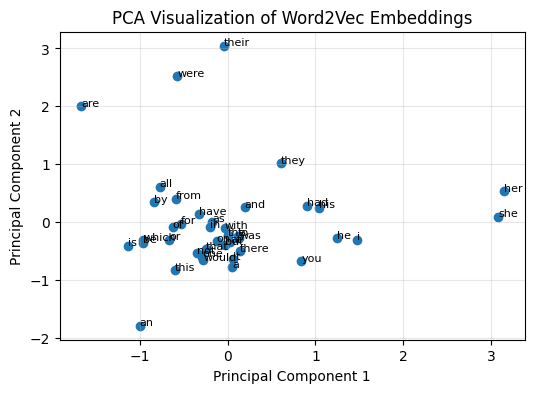

Explained variance ratio: [0.09178741 0.07410713]
Total variance represented by two components: 0.1659


In [9]:

words_to_plot = [
    word for word in word2vec_model.wv.index_to_key[:40]
    if word.isalpha()
]

word_vectors = np.array([
    word2vec_model.wv[word] for word in words_to_plot
])

pca = PCA(n_components=2, random_state=42)
reduced_vectors = pca.fit_transform(word_vectors)

plt.figure(figsize=(6,4))
plt.scatter(reduced_vectors[:, 0], reduced_vectors[:, 1])

for i, word in enumerate(words_to_plot):
    plt.annotate(
        word,
        (reduced_vectors[i, 0], reduced_vectors[i, 1]),
        fontsize=8
    )

plt.title("PCA Visualization of Word2Vec Embeddings")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(True, alpha=0.3)
plt.show()

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total variance represented by two components:",
      round(pca.explained_variance_ratio_.sum(), 4))


In [10]:

comparison = pd.DataFrame({
    "Technique": [
        "One-Hot Encoding",
        "Bag of Words",
        "TF-IDF",
        "Word2Vec Skip-gram",
        "GloVe",
        "FastText",
        "Keras Embedding",
        "BERT"
    ],
    "Representation": [
        "Sparse binary vector",
        "Word/document counts",
        "Weighted word counts",
        "Dense static word vector",
        "Dense static word vector",
        "Dense subword-aware vector",
        "Trainable dense vector",
        "Context-dependent vector"
    ],
    "Context Awareness": [
        "No", "No", "No", "Limited", "Limited",
        "Limited", "Depends on model", "Yes"
    ],
    "Rare/OOV Word Handling": [
        "Needs vocabulary", "Limited", "Limited",
        "Limited", "Limited",
        "Subword-based", "Needs OOV token",
        "Subword tokenization"
    ],
    "Main Limitation": [
        "Very high dimensionality",
        "Ignores word order",
        "Ignores deep meaning",
        "One vector per word",
        "One vector per word",
        "Training corpus matters",
        "Requires suitable training",
        "Higher compute requirements"
    ]
})

display(comparison)


,Technique,Representation,Context Awareness,Rare/OOV Word Handling,Main Limitation
0,One-Hot Encoding,Sparse binary vector,No,Needs vocabulary,Very high dimensionality
1,Bag of Words,Word/document counts,No,Limited,Ignores word order
2,TF-IDF,Weighted word counts,No,Limited,Ignores deep meaning
3,Word2Vec Skip-gram,Dense static word vector,Limited,Limited,One vector per word
4,GloVe,Dense static word vector,Limited,Limited,One vector per word
5,FastText,Dense subword-aware vector,Limited,Subword-based,Training corpus matters
6,Keras Embedding,Trainable dense vector,Depends on model,Needs OOV token,Requires suitable training
7,BERT,Context-dependent vector,Yes,Subword tokenization,Higher compute requirements


In [11]:

import os
import numpy as np

# Select the 100 most frequent words
words = word2vec_model.wv.index_to_key[:100]

# Extract their embedding vectors
vectors = np.array([
    word2vec_model.wv[word] for word in words
])

# Create a folder for the embedding project
os.makedirs("embedding_project", exist_ok=True)

# Save vectors in TSV format
np.savetxt(
    "embedding_project/vectors.tsv",
    vectors,
    delimiter="\t",
    fmt="%.6f"
)

# Save corresponding word labels
with open("embedding_project/metadata.tsv", "w", encoding="utf-8") as f:
    f.write("Word\n")
    for word in words:
        f.write(word + "\n")

print("Embedding project files created successfully!")
print("Number of words:", len(words))
print("Embedding dimensions:", vectors.shape[1])


Embedding project files created successfully!
Number of words: 100
Embedding dimensions: 100


In [12]:

from google.colab import files

files.download("embedding_project/vectors.tsv")
files.download("embedding_project/metadata.tsv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:

# Recreate metadata WITHOUT a header row
with open("embedding_project/metadata.tsv", "w", encoding="utf-8") as f:
    for word in words:
        f.write(word + "\n")

print("Metadata file fixed!")
print("Number of words:", len(words))


Metadata file fixed!
Number of words: 100


In [14]:

from google.colab import files

files.download("embedding_project/metadata.tsv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>